<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/07_How_To_Picture_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 7 — Cara Membayangkan Neural Network: di Kepala dan di Atas Kertas (*How to Picture Neural Networks*)

**Buku:** *Grokking Deep Learning* — Andrew W. Trask (Manning, 2019)

Bab 7 adalah bab **konseptual**: setelah Bab 3–6 membangun jaringan dari nol, kita belajar **menyederhanakan cara membayangkannya** agar bisa berpikir di tingkat arsitektur, bukan di tingkat bobot satu per satu. Buku tidak menyertakan kode untuk bab ini (tidak ada notebook resmi). Karena itu notebook ini memakai **kode ilustrasi (berlabel *Tambahan*)**: menggambar jaringan, melacak aliran data, dan memverifikasi bahwa gambar, huruf, dan kode menghasilkan angka yang sama.

---

## Daftar Isi
0. Persiapan: Jaringan dari Bab 6
1. Saatnya Menyederhanakan
2. Ringkasan Korelasi (*Correlation Summarization*)
3. Visualisasi yang Terlalu Rumit
4. Visualisasi yang Disederhanakan
5. Menyederhanakan Lebih Jauh: Dimensi Ditentukan oleh Layer
6. Melihat Jaringan Ini Memprediksi
7. Visualisasi dengan Huruf, Bukan Gambar
8. Menghubungkan Variabel
9. Semuanya Berdampingan
10. Pentingnya Alat Visualisasi
11. Tanya-Jawab Konsep dan Latihan
12. Ringkasan Bab

## 0. Persiapan: Jaringan dari Bab 6

Kita memakai kembali jaringan *streetlight* dari Bab 6 (3 input → 4 *hidden node* ReLU → 1 output) sebagai "kelinci percobaan" untuk semua visualisasi. Kode pelatihan **sama dengan Bab 6**, sehingga setiap gambar di bawah mewakili jaringan yang benar-benar sudah belajar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

np.random.seed(1)
relu = lambda x: (x > 0) * x
relu2deriv = lambda x: x > 0

streetlights = np.array([[1, 0, 1], [0, 1, 1], [0, 0, 1], [1, 1, 1]])
walk_vs_stop = np.array([[1, 1, 0, 0]]).T

alpha, hidden_size = 0.2, 4
weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

for iteration in range(60):
    for i in range(len(streetlights)):
        layer_0 = streetlights[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)
        layer_2_delta = layer_2 - walk_vs_stop[i:i+1]
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)

def forward(x):
    l1 = relu(x @ weights_0_1)
    return l1, l1 @ weights_1_2

print('Prediksi untuk keempat pola:', np.round([forward(s)[1].item() for s in streetlights], 3))
print('Target                     :', walk_vs_stop.ravel())

Prediksi untuk keempat pola: [1.    0.999 0.003 0.   ]
Target                     : [1 1 0 0]


---
## 1. Saatnya Menyederhanakan

Sejauh ini kita membayangkan neural network sebagai **kumpulan garis** (bobot) antar-lapisan node. Gambaran itu berguna untuk memahami cara kerja dasar. Namun makin kompleks jaringannya (puluhan layer, ribuan node), gambar seperti itu **terlalu penuh detail** untuk dipakai berpikir.

Kunci penyederhanaan adalah **ringkasan korelasi** (bagian 2): setelah kita tahu bahwa semua mekanisme belajar (*gradient descent*, *backpropagation*, *alpha*, dan seterusnya) bekerja secara konsisten, kita tidak perlu lagi memikirkan bagaimana **tiap bobot** diperbarui. Fokus kita berpindah ke **pertanyaan yang lebih tinggi**: *bagaimana layer-layer disusun, dan korelasi apa yang bisa ditemukan jaringan?*

---
## 2. Ringkasan Korelasi (*Correlation Summarization*)

Ringkasan inti seluruh pelajaran Bab 3–6, dalam dua tingkat:

> **Ringkasan korelasi lokal:** *setiap set bobot belajar mengorelasikan layer inputnya dengan apa yang diminta layer outputnya.*
>
> **Ringkasan korelasi global:** *apa yang harus dipelajari sebuah layer awal ditentukan oleh apa yang dibutuhkan layer-layer di sesudahnya.*

Artinya:
- Sebuah matriks bobot hanya melakukan satu hal: **menyesuaikan diri agar input layer sebelumnya berkorelasi dengan "permintaan" layer sesudahnya**.
- *Hidden layer* tidak punya target sendiri. "Target" bagi layer tersembunyi adalah **delta yang dikirim mundur** oleh layer di sesudahnya, yang berbunyi *"aku butuh sinyal lebih tinggi dari node ini"* atau *"aku butuh sinyal lebih rendah"*.
- Karena itu, jaringan bisa **menciptakan korelasi** di layer tengah bila dibutuhkan (Bab 6).

Kita lihat "permintaan" itu pada jaringan dengan bobot **awal** (sebelum dilatih), agar prediksi masih meleset dan permintaannya terlihat: tanda `layer_1_delta` menyatakan apakah layer 1 diminta menaikkan atau menurunkan sinyal.

In [2]:
# Tambahan (tidak ada di buku): "permintaan" layer berikutnya terhadap layer 1 (ringkasan korelasi global)
np.random.seed(1)
w01_awal = 2 * np.random.random((3, hidden_size)) - 1
w12_awal = 2 * np.random.random((hidden_size, 1)) - 1

x = streetlights[0:1]                      # pola [1,0,1], target 1 (jalan)
l1 = relu(x @ w01_awal)
l2 = l1 @ w12_awal
delta2 = l2 - walk_vs_stop[0:1]            # seberapa meleset output
delta1 = delta2.dot(w12_awal.T) * relu2deriv(l1)   # "permintaan" untuk layer 1 (diteruskan mundur)

print('layer_1 (aktivasi)      :', l1.round(2).ravel())
print('delta output            :', delta2.round(2).ravel(), '(negatif = output terlalu rendah)')
print('delta untuk tiap hidden :', delta1.round(2).ravel())
for k, d in enumerate(delta1.ravel()):
    if not relu2deriv(l1).ravel()[k]:
        print(f'  node {k}: tidak aktif (0) -> tidak menerima permintaan apa pun')
    else:
        print(f'  node {k}: ' + ('diminta menaikkan sinyal' if d < 0 else 'diminta menurunkan sinyal'))

layer_1 (aktivasi)      : [-0.    0.52 -0.   -0.  ]
delta output            : [-0.61] (negatif = output terlalu rendah)
delta untuk tiap hidden : [ 0.   -0.46  0.   -0.  ]
  node 0: tidak aktif (0) -> tidak menerima permintaan apa pun
  node 1: diminta menaikkan sinyal
  node 2: tidak aktif (0) -> tidak menerima permintaan apa pun
  node 3: tidak aktif (0) -> tidak menerima permintaan apa pun


**Interpretasi:** pada bobot awal ini hanya **satu hidden node** (node 1) yang aktif; tiga node lain mati (keluaran 0) sehingga tidak menerima permintaan apa pun, karena tidak berkontribusi pada prediksi. Output terlalu rendah (delta −0,61), jadi node 1, yang berbobot positif ke output, **diminta menaikkan sinyal** (delta −0,46). Bila bobotnya ke output negatif, permintaannya akan berbalik: menurunkan sinyal. Inilah ringkasan korelasi **global** dalam bentuk angka: *apa yang harus dipelajari layer awal ditentukan oleh kebutuhan layer berikutnya.*

---
## 3. Visualisasi yang Terlalu Rumit

Gambar berikut adalah cara kita membayangkan jaringan sejauh ini: setiap node dan **setiap bobot** digambar (biru = bobot positif, merah = negatif, makin tebal = makin besar). Gambar ini membantu belajar dasar, tetapi cepat tidak terbaca untuk jaringan besar.

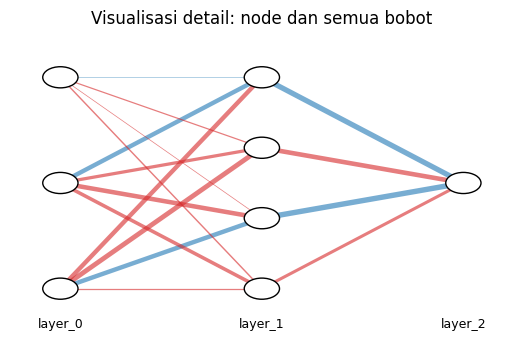

In [3]:
def draw_network(sizes, weights=None, activations=None, labels=None, ax=None, title=None):
    """Menggambar jaringan sebagai node dan garis bobot (visualisasi 'detail')."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4))
    xs = np.linspace(0.1, 0.9, len(sizes))
    pos = [[(xs[L], y) for y in (np.linspace(0.15, 0.85, n_) if n_ > 1 else [0.5])]
           for L, n_ in enumerate(sizes)]
    if weights is not None:
        wmax = max(np.abs(W).max() for W in weights)
        for L, W in enumerate(weights):
            for a, (x0, y0) in enumerate(pos[L]):
                for b, (x1, y1) in enumerate(pos[L + 1]):
                    w = W[a, b]
                    ax.plot([x0, x1], [y0, y1], color='tab:blue' if w > 0 else 'tab:red',
                            lw=0.4 + 3.5 * abs(w) / wmax, alpha=0.6, zorder=1)
    for L, pts in enumerate(pos):
        for k, (px, py) in enumerate(pts):
            ax.add_patch(Circle((px, py), 0.035, fc='white', ec='black', zorder=2))
            if activations is not None:
                ax.text(px, py, f'{activations[L][k]:.2f}', ha='center', va='center', fontsize=8, zorder=3)
        if labels:
            ax.text(xs[L], 0.02, labels[L], ha='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(-0.02, 1); ax.axis('off')
    if title: ax.set_title(title)
    return ax

draw_network([3, 4, 1], [weights_0_1, weights_1_2],
             labels=['layer_0', 'layer_1', 'layer_2'], title='Visualisasi detail: node dan semua bobot')
plt.show()

**Interpretasi:** 3×4 + 4×1 = **16 garis** untuk jaringan sekecil ini. Pada jaringan MNIST di Bab 8 (784 → 40 → 10) jumlahnya menjadi **31.760 garis**; menggambarnya tidak lagi berguna. Itulah alasan kita butuh gambaran yang lebih ringkas.

---
## 4. Visualisasi yang Disederhanakan

Alih-alih menggambar tiap bobot, kita memakai "balok LEGO":
- **Garis/strip** = *vektor* (sebuah layer),
- **Kotak** = *matriks* (kumpulan bobot antar-layer),
- Ukuran/shape dicantumkan, mis. `(1×3)`, `(3×4)`.

Alasan penyederhanaan ini sah: **semua mekanisme belajar tidak bergantung pada bagaimana "LEGO" disusun**. Bagaimanapun matriks dirangkai oleh layer, jaringan akan mencoba menemukan pola dengan mengubah bobot di antara input dan output.

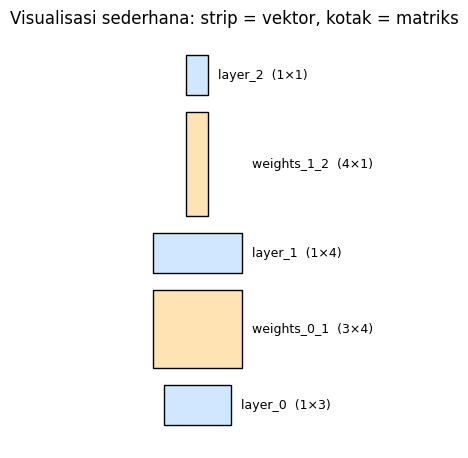

In [4]:
def draw_blocks(sizes, names=None, ax=None, title=None):
    """Visualisasi sederhana: strip = vektor (layer), kotak = matriks (bobot), lengkap dengan shape."""
    if ax is None:
        _, ax = plt.subplots(figsize=(4.8, 5.4))
    unit, y = 0.45, 0.0
    for L, n_ in enumerate(sizes):
        w = n_ * unit
        ax.add_patch(Rectangle((-w / 2, y), w, 0.35, fc='#cfe8ff', ec='black'))
        nm = names[2 * L] if names else f'layer_{L}'
        ax.text(w / 2 + 0.2, y + 0.17, f'{nm}  (1×{n_})', va='center', fontsize=9)
        y += 0.35
        if L < len(sizes) - 1:
            r, c = n_, sizes[L + 1]
            h, wc = r * unit * 0.5, c * unit
            ax.add_patch(Rectangle((-wc / 2, y + 0.15), wc, h, fc='#ffe3b3', ec='black'))
            nm2 = names[2 * L + 1] if names else f'weights_{L}_{L+1}'
            ax.text(max(wc, w) / 2 + 0.2, y + 0.15 + h / 2, f'{nm2}  ({r}×{c})', va='center', fontsize=9)
            y += h + 0.3
    ax.set_xlim(-3, 4.5); ax.set_ylim(-0.2, y + 0.2); ax.axis('off')
    if title: ax.set_title(title)
    return ax

draw_blocks([3, 4, 1], title='Visualisasi sederhana: strip = vektor, kotak = matriks')
plt.show()

**Interpretasi:** gambar ini tetap memuat **semua informasi yang diperlukan** untuk membangun jaringan: nama dan ukuran setiap layer serta setiap matriks. Detail tiap bobot tidak dibutuhkan karena kita sudah tahu bagaimana bobot-bobot itu akan diperbarui.

---
## 5. Menyederhanakan Lebih Jauh: Dimensi Ditentukan oleh Layer

Perhatikan polanya: **ukuran setiap matriks bobot ditentukan oleh dua layer di sisinya**. Jika layer sebelumnya berdimensi *m* dan sesudahnya *n*, matriks bobotnya pasti berukuran *m × n*, agar setiap node di layer pertama punya satu bobot ke tiap node di layer kedua. Jadi **cukup menggambar layer-nya**; matriks bobot dapat disimpulkan.

Ini mengarah ke konsep ***arsitektur***: susunan layer (dan bobot) pada neural network. Sebagian besar sisa buku membahas arsitektur yang berbeda-beda, karena arsitektur menentukan **seberapa mudah dan seberapa cepat** jaringan menemukan korelasi:

> *Arsitektur yang baik menyalurkan sinyal sehingga korelasi mudah ditemukan. Arsitektur yang hebat juga menyaring noise sehingga mencegah overfitting.*

In [5]:
# Tambahan (tidak ada di buku): menyimpulkan shape bobot dari ukuran layer saja
def infer_shapes(layer_sizes):
    return [(layer_sizes[i], layer_sizes[i + 1]) for i in range(len(layer_sizes) - 1)]

def jumlah_parameter(layer_sizes):
    return sum(m * n_ for m, n_ in infer_shapes(layer_sizes))

for nama, arsitektur in [('streetlight (Bab 6)', [3, 4, 1]),
                         ('MNIST 3-layer (Bab 8)', [784, 40, 10]),
                         ('MNIST lebih lebar', [784, 100, 10])]:
    print(f'{nama:24s} layer {arsitektur} -> shape bobot {infer_shapes(arsitektur)} | parameter = {jumlah_parameter(arsitektur):,}')

streetlight (Bab 6)      layer [3, 4, 1] -> shape bobot [(3, 4), (4, 1)] | parameter = 16
MNIST 3-layer (Bab 8)    layer [784, 40, 10] -> shape bobot [(784, 40), (40, 10)] | parameter = 31,760
MNIST lebih lebar        layer [784, 100, 10] -> shape bobot [(784, 100), (100, 10)] | parameter = 79,400


**Interpretasi:** dari daftar ukuran layer saja kita dapat menurunkan seluruh shape bobot dan jumlah parameter. Jumlah parameter adalah ukuran kasar **kapasitas** jaringan: makin banyak, makin besar kemampuan sekaligus risiko memorisasi (Bab 8).

---
## 6. Melihat Jaringan Ini Memprediksi

Kita ikuti satu data (pola lampu `[1, 0, 1]`) mengalir melalui jaringan:
1. `layer_0` diisi dengan data.
2. **Vector–matrix multiplication** dengan `weights_0_1` menghasilkan empat *weighted sum*, diletakkan di `layer_1`, lalu dilewatkan **ReLU** (nilai negatif menjadi 0).
3. Vector–matrix multiplication kedua dengan `weights_1_2` menghasilkan prediksi akhir di `layer_2`.

> **Ingat:** *vector–matrix multiplication* melakukan **beberapa weighted sum sekaligus**; jumlah baris matriks harus sama dengan panjang vektor, dan tiap kolom menghasilkan satu *weighted sum* berbeda.

layer_0                : [1 0 1]
weighted sum (pra-ReLU): [-0.372  0.877 -1.161 -0.898]
layer_1 (setelah ReLU) : [0.    0.877 0.    0.   ]  <- nilai negatif menjadi 0
layer_2 (prediksi)     : [1.] | target: [1]


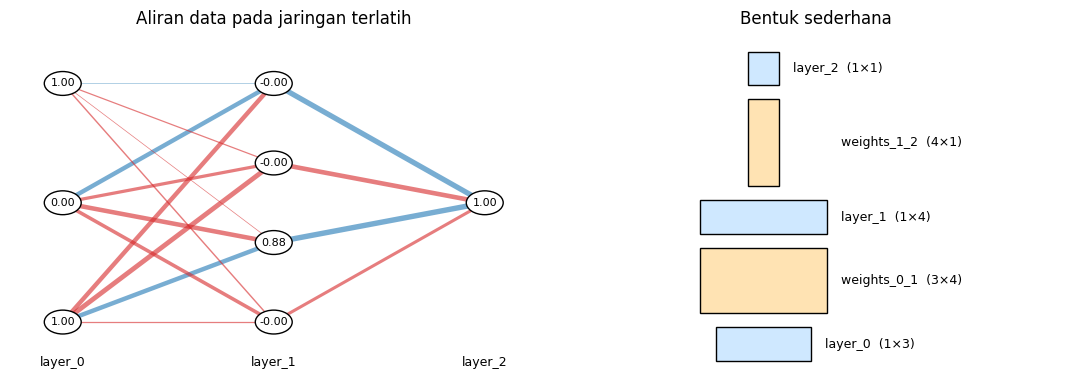

In [6]:
x = streetlights[0]                                  # [1, 0, 1]
langkah1 = x @ weights_0_1                           # empat weighted sum (sebelum ReLU)
langkah2 = relu(langkah1)                            # layer_1 setelah ReLU
langkah3 = langkah2 @ weights_1_2                    # prediksi akhir

print('layer_0                :', x)
print('weighted sum (pra-ReLU):', langkah1.round(3))
print('layer_1 (setelah ReLU) :', (langkah2 + 0.0).round(3), ' <- nilai negatif menjadi 0')
print('layer_2 (prediksi)     :', langkah3.round(3), '| target:', walk_vs_stop[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
draw_network([3, 4, 1], [weights_0_1, weights_1_2],
             activations=[x, langkah2, langkah3],
             labels=['layer_0', 'layer_1', 'layer_2'], ax=axes[0], title='Aliran data pada jaringan terlatih')
draw_blocks([3, 4, 1], ax=axes[1], title='Bentuk sederhana')
plt.tight_layout(); plt.show()

**Interpretasi:** angka di dalam node menunjukkan aktivasi tiap layer untuk pola `[1,0,1]`. Node yang weighted sum-nya negatif menjadi 0 setelah ReLU, dan prediksi akhir mendekati target 1. Gambar sederhana di kanan memuat shape yang sama dengan gambar detail di kiri.

---
## 7. Visualisasi dengan Huruf, Bukan Gambar

Gambar membantu, tetapi **huruf** lebih ringkas dan dapat dikomputasi (kita dapat "memanipulasi" persamaan). Konvensinya:
- **Matriks** → huruf **kapital**: $W_0$ (bobot antara layer 0 dan 1), $W_1$ (antara layer 1 dan 2).
- **Vektor** → huruf **kecil**: $l_0$, $l_1$, $l_2$ (layer). Huruf apa pun boleh dipakai; "$W$" untuk *weights* dan "$l$" untuk *layer* hanya agar mudah diingat. Angka kecil di bawah huruf membedakan beberapa matriks/vektor.

Maka seluruh jaringan dapat ditulis sebagai satu baris:
$$l_2=\text{relu}(l_0\,W_0)\,W_1$$
Persamaan ini **identik** dengan tiga baris kode di bagian 6.

In [7]:
# Tambahan (tidak ada di buku): notasi huruf = kode
W0, W1 = weights_0_1, weights_1_2
l0 = streetlights[0]

l1 = relu(l0 @ W0)            # l1 = relu(l0 W0)
l2 = l1 @ W1                  # l2 = l1 W1
satu_baris = relu(l0 @ W0) @ W1     # l2 = relu(l0 W0) W1

print('l2 (dua langkah)  :', l2.round(4))
print('l2 (satu baris)   :', satu_baris.round(4))
print('sama dengan kode "layer_2" di Bab 6?', np.allclose(l2, forward(streetlights[0:1])[1]))

l2 (dua langkah)  : [1.]
l2 (satu baris)   : [1.]
sama dengan kode "layer_2" di Bab 6? True


---
## 8. Menghubungkan Variabel

Tiga bahasa untuk objek yang sama:

| Objek | Gambar | Huruf | Kode Python | Shape |
|---|---|---|---|---|
| Data input | strip | $l_0$ | `layer_0` | (1×3) |
| Bobot input→hidden | kotak | $W_0$ | `weights_0_1` | (3×4) |
| Layer tersembunyi | strip | $l_1$ | `layer_1` | (1×4) |
| Bobot hidden→output | kotak | $W_1$ | `weights_1_2` | (4×1) |
| Prediksi | strip | $l_2$ | `layer_2` | (1×1) |

Kemampuan **berpindah dengan lancar** antara gambar, huruf, dan kode adalah inti bab ini: makalah riset biasanya memakai huruf, buku ajar memakai gambar, dan implementasi memakai kode.

---
## 9. Semuanya Berdampingan

Kita buktikan ketiga representasi menghasilkan angka yang sama untuk keempat pola lampu.

In [8]:
# Tambahan (tidak ada di buku): gambar = huruf = kode untuk semua pola
print('pola lampu | l2 (huruf) | layer_2 (kode Bab 6) | selisih')
for s in streetlights:
    huruf = relu(s @ W0) @ W1
    kode  = forward(s[None, :])[1]
    print(f'{s} | {huruf.item():10.4f} | {kode.item():20.4f} | {abs(huruf.item() - kode.item()):.1e}')

pola lampu | l2 (huruf) | layer_2 (kode Bab 6) | selisih
[1 0 1] |     1.0000 |               1.0000 | 0.0e+00
[0 1 1] |     0.9986 |               0.9986 | 0.0e+00
[0 0 1] |     0.0026 |               0.0026 | 0.0e+00
[1 1 1] |     0.0000 |               0.0000 | 0.0e+00


**Interpretasi:** selisihnya 0: tidak ada informasi yang hilang saat berpindah antar-representasi. Gambar sederhana memang menyembunyikan nilai bobot, tetapi tetap cukup untuk membangun dan menalar jaringan.

---
## 10. Pentingnya Alat Visualisasi

Prinsip yang ditekankan bab ini: **kita berpikir tentang jaringan dengan alat visual yang sesuai tingkat abstraksinya.**
- Saat *belajar dasar*: gambar detail (node dan bobot).
- Saat *merancang arsitektur*: balok/strip dan shape.
- Saat *membaca makalah atau menurunkan rumus*: notasi huruf.
- Saat *mengimplementasikan*: kode.

Bila sebuah gambar atau persamaan di makalah tampak rumit, **terjemahkan** ke bentuk yang lebih sederhana ini. Hampir semua arsitektur di bab-bab berikutnya (regularisasi, aktivasi, CNN, embedding, RNN, LSTM) hanyalah susunan "LEGO" yang berbeda.

---
## 11. Tanya-Jawab Konsep dan Latihan

**1. Apa isi ringkasan korelasi lokal dan global?** *Lokal:* tiap set bobot belajar mengorelasikan layer inputnya dengan permintaan layer outputnya. *Global:* apa yang dipelajari layer awal ditentukan oleh kebutuhan layer di sesudahnya.

**2. Mengapa kita tidak lagi menggambar setiap bobot?** Karena detail pembaruan bobot sudah dijamin oleh mekanisme belajar; yang menentukan keberhasilan adalah **arsitektur** (susunan layer), bukan nilai tiap bobot.

**3. Bagaimana menyimpulkan shape matriks bobot?** Dari dimensi dua layer di sisinya: layer *m* dan layer *n* → matriks *m × n*.

**4. Apa arti "arsitektur yang baik"?** Menyalurkan sinyal sehingga korelasi mudah ditemukan, dan (bila hebat) menyaring noise sehingga tidak overfit.

**5. Mengapa *vector–matrix multiplication* disebut "beberapa weighted sum sekaligus"?** Tiap kolom matriks bobot adalah satu "template"; mengalikan vektor dengan matriks menghitung *dot product* vektor dengan setiap kolom.

### Latihan mandiri
1. Gambar arsitektur 5 → 8 → 3 → 1 dengan `draw_blocks`, dan hitung jumlah parameternya.
2. Tulis persamaan huruf untuk jaringan dengan *tiga* matriks bobot ($W_0, W_1, W_2$) dan dua ReLU.
3. Buktikan bahwa dua layer *linear* ($l_2 = l_0 W_0 W_1$) setara satu matriks $W = W_0 W_1$.

1) shape bobot: [(5, 8), (8, 3), (3, 1)] | parameter = 67


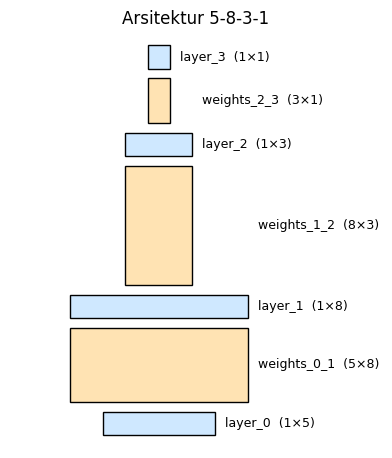

2) l3 = relu(relu(l0 W0) W1) W2
3) dua layer linear == satu matriks gabungan? True


In [9]:
# Jawaban latihan mandiri (Tambahan)
arsitektur = [5, 8, 3, 1]
print('1) shape bobot:', infer_shapes(arsitektur), '| parameter =', jumlah_parameter(arsitektur))
draw_blocks(arsitektur, title='Arsitektur 5-8-3-1')
plt.show()

print('2) l3 = relu(relu(l0 W0) W1) W2')

rng = np.random.default_rng(0)
A, B = rng.normal(size=(3, 4)), rng.normal(size=(4, 2)); v = rng.normal(size=(1, 3))
print('3) dua layer linear == satu matriks gabungan?', np.allclose(v @ A @ B, v @ (A @ B)))

---
## 12. Ringkasan Bab

- **Ringkasan korelasi:** *lokal*: tiap set bobot mengorelasikan input-nya dengan permintaan output-nya; *global*: layer awal belajar apa yang dibutuhkan layer berikutnya.
- Visualisasi **sederhana**: strip = vektor, kotak = matriks; ukuran matriks ditentukan oleh layer di sisinya.
- **Arsitektur** (susunan layer dan bobot) menentukan seberapa mudah korelasi ditemukan dan apakah noise tersaring.
- Gambar, huruf ($l_0$, $W_0$, …), dan kode adalah tiga bahasa untuk hal yang sama; kita berpindah di antaranya sesuai kebutuhan.

### Rangkuman konsep
| Subbab | Konsep | Wujud |
|---|---|---|
| Ringkasan korelasi | Lokal & global | `layer_1_delta` sebagai "permintaan" |
| Visualisasi detail | Node + bobot | `draw_network` |
| Visualisasi sederhana | Strip & kotak | `draw_blocks` |
| Dimensi | $m \times n$ dari layer | `infer_shapes` |
| Prediksi | Aliran data | langkah 1–3 |
| Notasi huruf | $l_2=\text{relu}(l_0W_0)W_1$ | Kode identik |